# Прогноз почасового спроса на велопрокат (hour.csv) на 24 часа вперёд: ARIMA, LSTM, CNN, CNN+LSTM

**Задача:** в момент `t` по истории до `t-1` включительно спрогнозировать число аренд `cnt` сразу на **24 часа вперёд**: `t, t+1, …, t+23`.
Прогноз делается из каждого часа тестового периода.

**Модели:**
1. **SARIMAX** — сезонная ARIMA (сезон 24 ч) с экзогенными признаками, многошаговый прогноз `get_forecast(24)` (внутри рекурсивный);
2. **LSTM** — рекуррентная сеть;
3. **CNN** — свёрточная сеть (каузальные dilated-свёртки, TCN-подобная);
4. **CNN + LSTM** — свёртки извлекают локальные паттерны, LSTM моделирует их последовательность.

Нейросети прогнозируют **прямо** (direct / MIMO): за один проход выдают сразу 24 значения, без подстановки собственных прогнозов.



In [47]:
import warnings
warnings.filterwarnings("ignore")

import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

plt.rcParams["figure.figsize"] = (14, 4)

device: cuda


# Загрузка данных

In [48]:
raw = pd.read_csv("../lessons/hour.csv", parse_dates=["dteday"])
raw["datetime"] = raw["dteday"] + pd.to_timedelta(raw["hr"], unit="h")
raw = raw.set_index("datetime").sort_index()

print(raw.shape, raw.index.min(), "->", raw.index.max())
raw.head()

(17379, 17) 2011-01-01 00:00:00 -> 2012-12-31 23:00:00


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
datetime,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
2011-01-01 01:00:00,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2011-01-01 02:00:00,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
2011-01-01 03:00:00,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
2011-01-01 04:00:00,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
full_idx = pd.date_range(raw.index.min(), raw.index.max(), freq="h")
missing = full_idx.difference(raw.index)
print("Всего часов в диапазоне:", len(full_idx))
print("Пропущенных часов:", len(missing))
print(pd.Series(missing.hour).value_counts().sort_index().to_string())

Всего часов в диапазоне: 17544
Пропущенных часов: 165
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3


# Подготовка ряда

* сетка выравнивается до ровной почасовой; пропущенные часы: `cnt = 0`, погода интерполируется, календарь пересчитывается по дате;
* `casual` и `registered` **не используем** — это слагаемые `cnt` (утечка таргета);
* целевая переменная моделируется в виде `y = log1p(cnt)` — ряд сильно скошен и дисперсия растёт с уровнем;
* при оценке качества пропущенные (заполненные) часы не учитываются.

In [50]:
data = pd.DataFrame(index=full_idx)
data["cnt"] = raw["cnt"].reindex(full_idx).fillna(0)
data["observed"] = full_idx.isin(raw.index)

for c in ["temp", "atemp", "hum", "windspeed"]:
    data[c] = raw[c].reindex(full_idx).interpolate().bfill()
data["weathersit"] = raw["weathersit"].reindex(full_idx).ffill().bfill()

# праздник/рабочий день — дневные признаки, берём по дате
day_info = raw.groupby("dteday")[["holiday", "workingday"]].first()
dates = pd.Series(full_idx.normalize(), index=full_idx)
data["holiday"] = dates.map(day_info["holiday"]).fillna(0)
data["workingday"] = dates.map(day_info["workingday"]).fillna(
    pd.Series((full_idx.dayofweek < 5).astype(int), index=full_idx))

# циклическое кодирование календаря
hour = full_idx.hour.values
dow = full_idx.dayofweek.values
doy = full_idx.dayofyear.values
data["hour_sin"], data["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
data["dow_sin"], data["dow_cos"] = np.sin(2 * np.pi * dow / 7), np.cos(2 * np.pi * dow / 7)
data["doy_sin"], data["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
data["year"] = (full_idx.year == 2012).astype(int)   # рост сервиса 2011 -> 2012

data["y"] = np.log1p(data["cnt"])

assert not data.isna().any().any()
data.head()

,cnt,observed,temp,atemp,hum,windspeed,weathersit,holiday,workingday,hour_sin,hour_cos,dow_sin,dow_cos,doy_sin,doy_cos,year,y
2011-01-01 00:00:00,16.0,True,0.24,0.2879,0.81,0.0,1.0,0,0,0.000000,1.000000,-0.974928,-0.222521,0.017202,0.999852,0,2.833213
2011-01-01 01:00:00,40.0,True,0.22,0.2727,0.80,0.0,1.0,0,0,0.258819,0.965926,-0.974928,-0.222521,0.017202,0.999852,0,3.713572
2011-01-01 02:00:00,32.0,True,0.22,0.2727,0.80,0.0,1.0,0,0,0.500000,0.866025,-0.974928,-0.222521,0.017202,0.999852,0,3.496508
2011-01-01 03:00:00,13.0,True,0.24,0.2879,0.75,0.0,1.0,0,0,0.707107,0.707107,-0.974928,-0.222521,0.017202,0.999852,0,2.639057
2011-01-01 04:00:00,1.0,True,0.24,0.2879,0.75,0.0,1.0,0,0,0.866025,0.500000,-0.974928,-0.222521,0.017202,0.999852,0,0.693147


## Разбиение по времени

train: 16080 ч, val: 720 ч, test: 744 ч


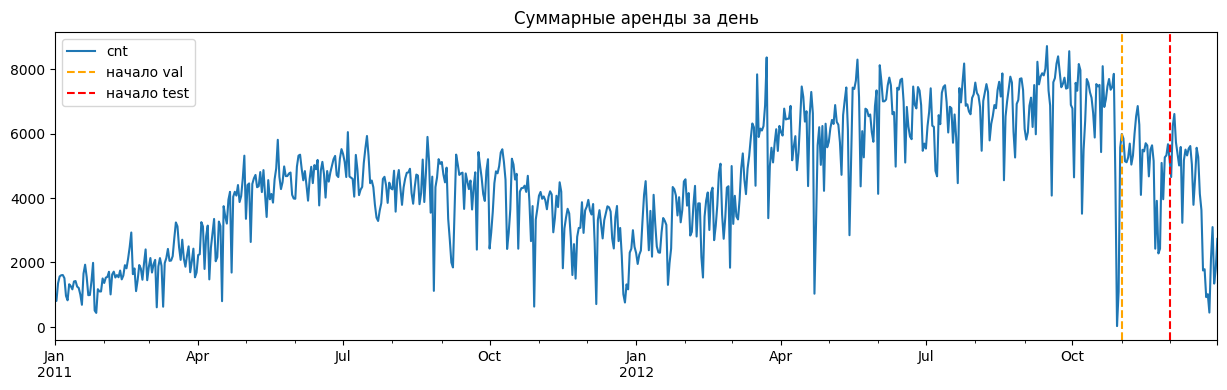

In [51]:
VAL_START = pd.Timestamp("2012-11-01")    # валидация: ноябрь 2012 (ранняя остановка нейросетей)
TEST_START = pd.Timestamp("2012-12-01")   # тест: декабрь 2012 (последний месяц)

is_train = data.index < VAL_START
is_val = (data.index >= VAL_START) & (data.index < TEST_START)
is_test = data.index >= TEST_START
print(f"train: {is_train.sum()} ч, val: {is_val.sum()} ч, test: {is_test.sum()} ч")

fig, ax = plt.subplots(figsize=(15, 4))
data["cnt"].resample("D").sum().plot(ax=ax)
ax.axvline(VAL_START, color="orange", ls="--", label="начало val")
ax.axvline(TEST_START, color="red", ls="--", label="начало test")
ax.set_title("Суммарные аренды за день")
ax.legend()
plt.show()

# EDA: сезонность

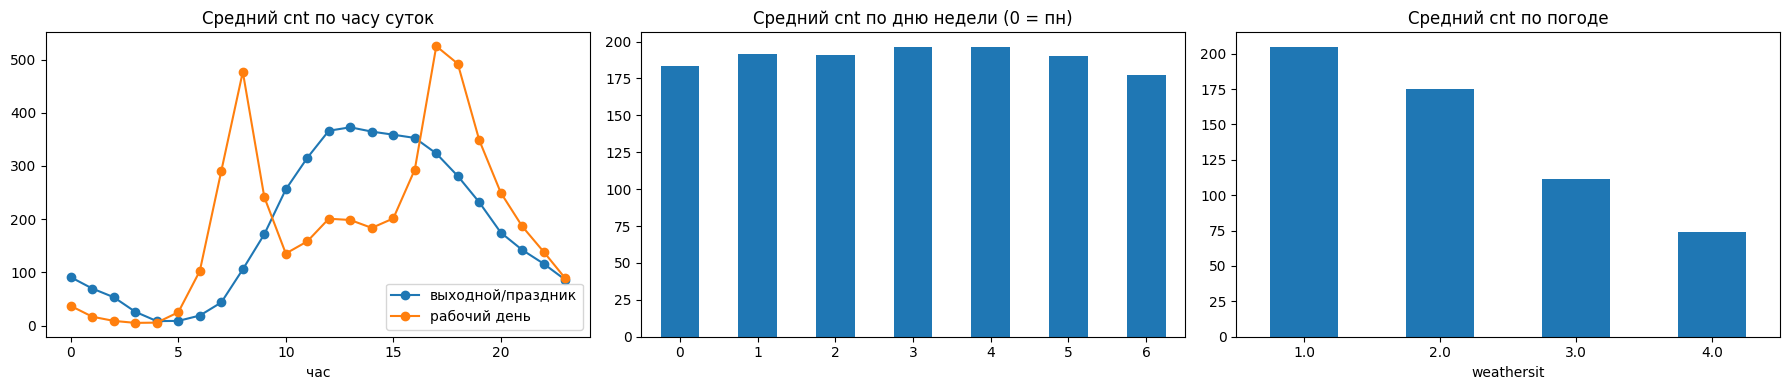

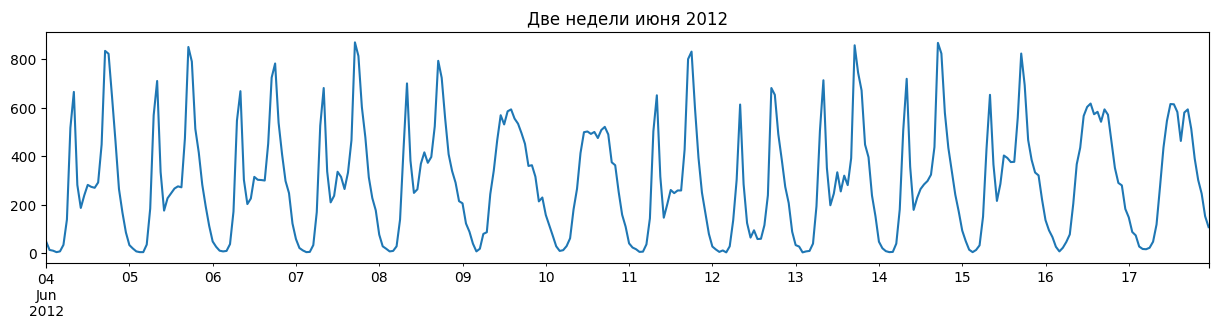

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

obs = data[data["observed"]]
prof = obs.groupby([obs.index.hour, "workingday"])["cnt"].mean().unstack()
prof.columns = ["выходной/праздник", "рабочий день"]
prof.plot(ax=axes[0], marker="o")
axes[0].set_title("Средний cnt по часу суток")
axes[0].set_xlabel("час")

obs.groupby(obs.index.dayofweek)["cnt"].mean().plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Средний cnt по дню недели (0 = пн)")

obs.groupby("weathersit")["cnt"].mean().plot.bar(ax=axes[2], rot=0)
axes[2].set_title("Средний cnt по погоде")
plt.tight_layout()
plt.show()

# две недели крупным планом
data.loc["2012-06-04":"2012-06-17", "cnt"].plot(figsize=(15, 3), title="Две недели июня 2012")
plt.show()

# Постановка прогноза на 24 часа

* `H = 24` — горизонт, `LOOKBACK` — сколько часов истории видит модель.
* **Точка прогноза** (origin) `t`: известна история до `t-1`, прогнозируем `t … t+H-1`.
* Календарь будущих часов известен точно. Погода — нет; флаг `USE_FUTURE_WEATHER`:
  * `True` — считаем, что есть (идеальный) прогноз погоды на сутки, и подаём погоду будущих часов;
  * `False` — погода только из истории, будущее — только календарь (более честная, но и более сложная постановка).
* Тест: все точки прогноза из декабря 2012, у которых все 24 часа горизонта есть в данных.

In [ ]:
H = 24
LOOKBACK = 72               
USE_FUTURE_WEATHER = True

WEATHER = ["temp", "atemp", "hum", "windspeed", "weathersit"]
CALENDAR = ["holiday", "workingday", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "doy_sin", "doy_cos", "year"]
EXOG = WEATHER + CALENDAR

last_hour = data.index[-1]
test_origins = data.index[(data.index >= TEST_START) & (data.index <= last_hour - pd.Timedelta(hours=H - 1))]
print("Точек прогноза в тесте:", len(test_origins), "|", test_origins[0], "->", test_origins[-1])

cnt_arr = data["cnt"].values
obs_arr = data["observed"].values
pos = data.index.get_indexer(test_origins)
steps = np.arange(H)
Y_TRUE = cnt_arr[pos[:, None] + steps]       # (n_origins, H)
OBS = obs_arr[pos[:, None] + steps]          # заполненные (пропущенные) часы в метриках не учитываем
print("Y_TRUE:", Y_TRUE.shape, "| доля наблюдённых:", OBS.mean().round(4))

Точек прогноза в тесте: 721 | 2012-12-01 00:00:00 -> 2012-12-31 00:00:00
Y_TRUE: (721, 24) | доля наблюдённых: 0.9972


# Метрики и baseline'ы

In [54]:
def metrics(P, name):
    t, p = Y_TRUE[OBS], P[OBS]
    return {"model": name,
            "RMSE": np.sqrt(mean_squared_error(t, p)),
            "MAE": mean_absolute_error(t, p),
            "R2": r2_score(t, p)}

def rmse_by_step(P):
    return np.array([np.sqrt(np.mean((P[OBS[:, k], k] - Y_TRUE[OBS[:, k], k]) ** 2)) for k in range(H)])

predictions = {}   # name -> матрица прогнозов cnt (n_origins, H)
predictions["Naive (последний час)"] = np.repeat(cnt_arr[pos - 1][:, None], H, axis=1)
predictions["Naive (сутки назад)"] = cnt_arr[pos[:, None] + steps - 24]
predictions["Naive (неделя назад)"] = cnt_arr[pos[:, None] + steps - 168]

pd.DataFrame([metrics(p, n) for n, p in predictions.items()]).round(3)

,model,RMSE,MAE,R2
0,Naive (последний час),212.701,154.488,-0.647
1,Naive (сутки назад),100.751,59.289,0.630
2,Naive (неделя назад),111.005,64.378,0.551


# 1. SARIMAX

* ряд `y = log1p(cnt)`, сезонная часть с периодом **24 ч**;
* экзогенные признаки: `workingday`, `holiday`, гармоники суток (sin/cos, k = 1..4) **и их произведения с `workingday`** — чтобы модель различала «двугорбый» профиль рабочего дня и профиль выходного; погода — если `USE_FUTURE_WEATHER`;
* параметры оцениваются на последних `ARIMA_TRAIN_WEEKS` неделях train (на всех ~15 тыс. часов сезонная модель обучается очень долго);
* на тесте параметры **зафиксированы**: из каждой точки прогноза делаем `get_forecast(24)`, затем добавляем в модель следующий фактический час (`extend`) и переходим к следующей точке.

In [55]:
def build_arima_exog(d, k_max=4, use_weather=USE_FUTURE_WEATHER):
    ex = d[["holiday", "workingday"]].copy()
    if use_weather:
        ex[["temp", "hum", "windspeed"]] = d[["temp", "hum", "windspeed"]]
        ex["bad_weather"] = (d["weathersit"] >= 3).astype(int)
    h = d.index.hour.values
    for k in range(1, k_max + 1):
        s, c = np.sin(2 * np.pi * k * h / 24), np.cos(2 * np.pi * k * h / 24)
        ex[f"s{k}"], ex[f"c{k}"] = s, c
        ex[f"s{k}_wd"], ex[f"c{k}_wd"] = s * d["workingday"].values, c * d["workingday"].values
    return ex.astype(float)

arima_exog = build_arima_exog(data)
print(arima_exog.shape)

(17544, 22)


Окно обучения ARIMA: 2012-09-06 00:00:00 -> 2012-10-31 23:00:00 1344 ч
ADF p-value: исходный ряд = 0.0874, после сезонной разности (24) = 0.0000


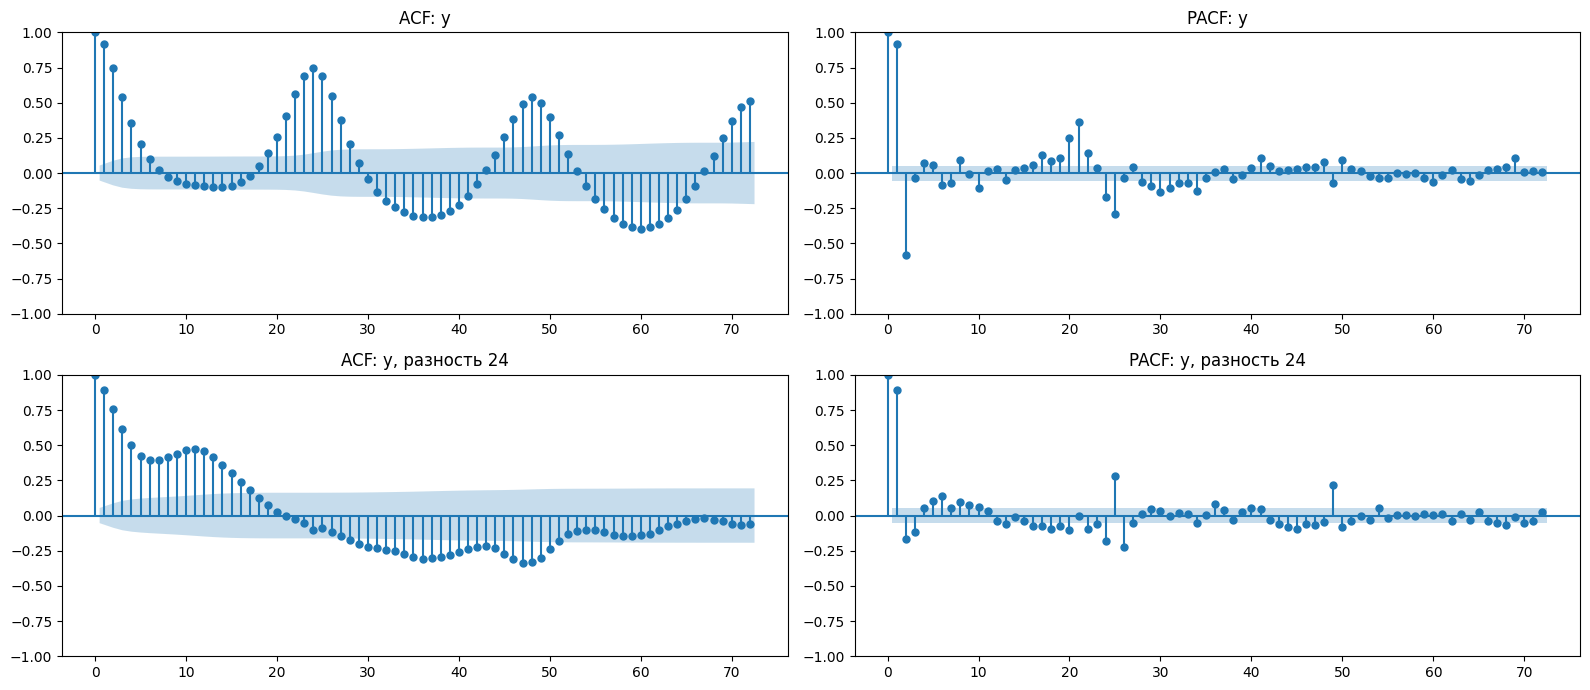

In [56]:
ARIMA_TRAIN_WEEKS = 8
arima_fit_start = VAL_START - pd.Timedelta(weeks=ARIMA_TRAIN_WEEKS)
y_arima_train = data.loc[arima_fit_start:VAL_START - pd.Timedelta(hours=1), "y"]
print("Окно обучения ARIMA:", y_arima_train.index.min(), "->", y_arima_train.index.max(), len(y_arima_train), "ч")

adf_p = adfuller(y_arima_train, autolag="AIC")[1]
adf_p_s = adfuller(y_arima_train.diff(24).dropna(), autolag="AIC")[1]
print(f"ADF p-value: исходный ряд = {adf_p:.4f}, после сезонной разности (24) = {adf_p_s:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(16, 7))
plot_acf(y_arima_train, lags=72, ax=axes[0, 0], title="ACF: y")
plot_pacf(y_arima_train, lags=72, ax=axes[0, 1], method="ywm", title="PACF: y")
y_s = y_arima_train.diff(24).dropna()
plot_acf(y_s, lags=72, ax=axes[1, 0], title="ACF: y, разность 24")
plot_pacf(y_s, lags=72, ax=axes[1, 1], method="ywm", title="PACF: y, разность 24")
plt.tight_layout()
plt.show()

In [79]:
ARIMA_ORDER = (2, 0, 5)             # (p, d, q)
ARIMA_SEASONAL = (1, 0, 1, 24)      # (P, D, Q, s)

t0 = time.time()
arima_res = SARIMAX(y_arima_train, exog=arima_exog.loc[y_arima_train.index],
                    order=ARIMA_ORDER, seasonal_order=ARIMA_SEASONAL, trend="c",
                    enforce_stationarity=False, enforce_invertibility=False
                    ).fit(disp=False, maxiter=200)
print(f"Обучение заняло {time.time() - t0:.1f} с")
print(arima_res.summary().tables[1])
print("AIC:", round(arima_res.aic, 1))

Обучение заняло 120.5 с
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
intercept       0.0003      0.001      0.502      0.616      -0.001       0.001
holiday        -0.2261      0.383     -0.591      0.555      -0.976       0.524
workingday     -0.3352      0.126     -2.667      0.008      -0.582      -0.089
temp            4.7955      0.527      9.103      0.000       3.763       5.828
hum             0.7768      0.254      3.063      0.002       0.280       1.274
windspeed      -0.1952      0.149     -1.311      0.190      -0.487       0.097
bad_weather    -0.0767      0.047     -1.617      0.106      -0.170       0.016
s1             -1.3455      0.608     -2.214      0.027      -2.536      -0.155
c1             -0.7102      0.631     -1.125      0.261      -1.948       0.527
s1_wd           0.1822      0.112      1.632      0.103      -0.037       0.401
c1_wd           

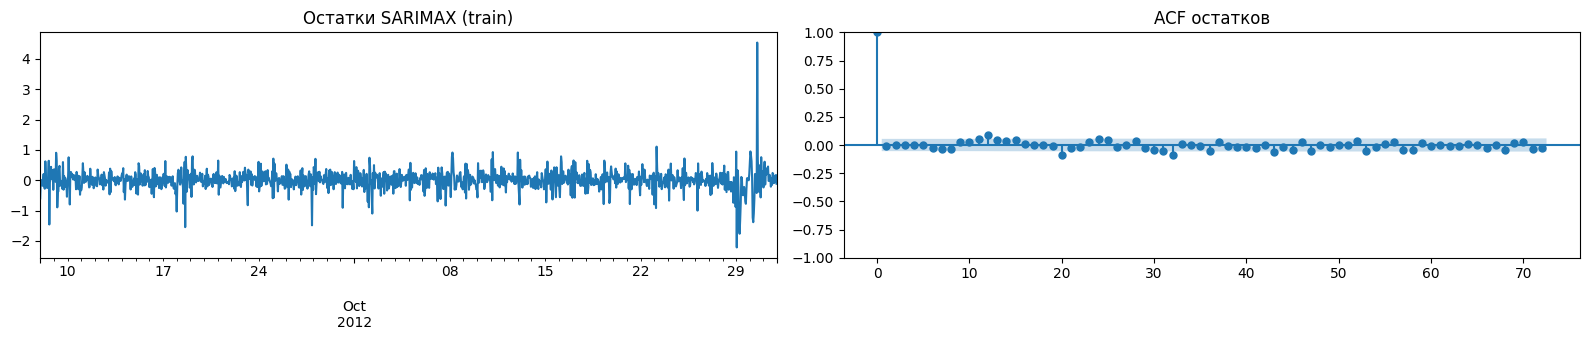

In [80]:
# остатки на обучении
resid = arima_res.resid.iloc[48:]
fig, axes = plt.subplots(1, 2, figsize=(16, 3.5))
resid.plot(ax=axes[0], title="Остатки SARIMAX (train)")
plot_acf(resid, lags=72, ax=axes[1], title="ACF остатков")
plt.tight_layout()
plt.show()

In [81]:
# скользящий прогноз на 24 часа из каждой точки теста, параметры зафиксированы
y_log = data["y"]
hist_end = TEST_START - pd.Timedelta(hours=1)
cur = arima_res.apply(y_log.loc[arima_fit_start:hist_end], exog=arima_exog.loc[arima_fit_start:hist_end])

P_log = np.zeros((len(test_origins), H))
t0 = time.time()
for i, t in enumerate(test_origins):
    if i > 0:   # добавляем фактический час t-1 к истории
        prev = [test_origins[i - 1]]
        cur = cur.extend(y_log.loc[prev].values, exog=arima_exog.loc[prev].values)
    fut = pd.date_range(t, periods=H, freq="h")
    P_log[i] = np.asarray(cur.forecast(H, exog=arima_exog.loc[fut].values))
    if i % 100 == 0:
        print(f"{i}/{len(test_origins)}  ({time.time() - t0:.0f} с)")

predictions["SARIMAX"] = np.expm1(P_log).clip(min=0)
metrics(predictions["SARIMAX"], "SARIMAX")

0/721  (0 с)
100/721  (1 с)
200/721  (3 с)
300/721  (4 с)
400/721  (5 с)
500/721  (7 с)
600/721  (8 с)
700/721  (9 с)


{'model': 'SARIMAX',
 'RMSE': 99.14671114738681,
 'MAE': 62.074049995944996,
 'R2': 0.6420575098396705}

# 2–4. Нейросети: подготовка данных

Вход сети — последовательность длины `LOOKBACK + H`:
* первые `LOOKBACK` шагов — **история**: экзогенные признаки + `y` (стандартизованный `log1p(cnt)`);
* последние `H` шагов — **будущее**: календарь (+ погода, если `USE_FUTURE_WEATHER`), `y` обнулён, флаг `is_future = 1`.

Сеть выдаёт по одному числу на каждый из `H` будущих шагов → сразу 24 прогноза (прямая стратегия).
Все модели каузальные: выход в будущем шаге `t+k` зависит только от истории и признаков будущих шагов до `t+k`.

Признаки стандартизуются, scaler обучается только на train.

In [82]:
SEQ = LOOKBACK + H

x_scaler = StandardScaler().fit(data.loc[is_train, EXOG])
y_mean, y_std = data.loc[is_train, "y"].mean(), data.loc[is_train, "y"].std()

E = x_scaler.transform(data[EXOG]).astype("float32")                      # (T, n_exog)
Yz = ((data["y"].values - y_mean) / y_std).astype("float32")              # (T,)
A = np.hstack([E, Yz[:, None], np.zeros((len(E), 1), dtype="float32")])  # + y + флаг is_future

Y_COL, FLAG_COL = len(EXOG), len(EXOG) + 1
WEATHER_COLS = [EXOG.index(c) for c in WEATHER]
N_FEATURES = A.shape[1]

# окно s: строки [s, s + SEQ); точка прогноза t = s + LOOKBACK
X_all = np.lib.stride_tricks.sliding_window_view(A, SEQ, axis=0).transpose(0, 2, 1).copy()  # (n, SEQ, F)
X_all[:, LOOKBACK:, Y_COL] = 0.0        # будущий спрос неизвестен
X_all[:, LOOKBACK:, FLAG_COL] = 1.0
if not USE_FUTURE_WEATHER:
    X_all[:, LOOKBACK:, WEATHER_COLS] = 0.0
Y_all = np.lib.stride_tricks.sliding_window_view(Yz, H)[LOOKBACK:LOOKBACK + len(X_all)].copy()   # (n, H)
O_all = data.index[LOOKBACK:LOOKBACK + len(X_all)]                                                # точки прогноза
assert len(X_all) == len(Y_all) == len(O_all)

horizon_end = O_all + pd.Timedelta(hours=H - 1)
w_train = horizon_end < VAL_START                              # весь горизонт внутри train
w_val = (O_all >= VAL_START) & (horizon_end < TEST_START)
w_test = O_all >= TEST_START
assert (O_all[w_test] == test_origins).all()

print("X:", X_all.shape, "| Y:", Y_all.shape, "| features:", N_FEATURES)
print(f"окон: train {w_train.sum()}, val {w_val.sum()}, test {w_test.sum()}")

X: (17449, 96, 16) | Y: (17449, 24) | features: 16
окон: train 15985, val 697, test 721


In [83]:
BATCH = 128

def make_dataset(mask):
    return TensorDataset(torch.from_numpy(X_all[mask]), torch.from_numpy(Y_all[mask]))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(make_dataset(w_train), batch_size=BATCH, shuffle=True, drop_last=True, generator=g)
val_loader = DataLoader(make_dataset(w_val), batch_size=BATCH, shuffle=False)
test_loader = DataLoader(make_dataset(w_test), batch_size=BATCH, shuffle=False)

## Модели

In [84]:
def make_head(in_dim, dropout):
    # одна и та же голова применяется к каждому из H будущих шагов
    return nn.Sequential(nn.Linear(in_dim, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))


class LSTMModel(nn.Module):
    # 2-слойная LSTM по всей последовательности (история + будущее), выходы на последних H шагах
    def __init__(self, n_features, hidden=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.rnn = nn.LSTM(n_features, hidden, num_layers=num_layers, batch_first=True, dropout=dropout)
        self.head = make_head(hidden, dropout)

    def forward(self, x):                        # x: (B, SEQ, F)
        out, _ = self.rnn(x)                     # (B, SEQ, hidden)
        return self.head(out[:, -H:]).squeeze(-1)   # (B, H)


class CausalConv1d(nn.Conv1d):
    # свёртка, которая не заглядывает в будущее: паддинг только слева
    def __init__(self, in_ch, out_ch, kernel_size, dilation=1):
        super().__init__(in_ch, out_ch, kernel_size, dilation=dilation)
        self.left_pad = (kernel_size - 1) * dilation

    def forward(self, x):
        return super().forward(F.pad(x, (self.left_pad, 0)))


class TCNBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel_size, dilation, dropout):
        super().__init__()
        self.net = nn.Sequential(
            CausalConv1d(in_ch, out_ch, kernel_size, dilation), nn.BatchNorm1d(out_ch), nn.ReLU(), nn.Dropout(dropout),
            CausalConv1d(out_ch, out_ch, kernel_size, dilation), nn.BatchNorm1d(out_ch), nn.ReLU(), nn.Dropout(dropout),
        )
        self.skip = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        return F.relu(self.net(x) + self.skip(x))


class CNNModel(nn.Module):
    # TCN: стек residual-блоков с dilation 1, 2, 4, 8, 16
    # рецептивное поле = 1 + 2*(k-1)*sum(dilations) = 1 + 2*2*31 = 125 ч >= SEQ (96 при LOOKBACK=72)
    def __init__(self, n_features, channels=64, kernel_size=3, dilations=(1, 2, 4, 8, 16), dropout=0.2):
        super().__init__()
        blocks, in_ch = [], n_features
        for d in dilations:
            blocks.append(TCNBlock(in_ch, channels, kernel_size, d, dropout))
            in_ch = channels
        self.tcn = nn.Sequential(*blocks)
        self.head = make_head(channels, dropout)

    def forward(self, x):                        # x: (B, SEQ, F)
        h = self.tcn(x.transpose(1, 2))          # (B, C, SEQ)
        return self.head(h[:, :, -H:].transpose(1, 2)).squeeze(-1)   # (B, H)


class CNNLSTMModel(nn.Module):
    # свёртки выделяют локальные паттерны (окрестность в несколько часов),
    # LSTM обрабатывает последовательность свёрточных признаков
    # (без pooling: нужен выход на каждом из H будущих часов)
    def __init__(self, n_features, channels=64, kernel_size=3, hidden=64, dropout=0.2):
        super().__init__()
        self.conv = nn.Sequential(
            CausalConv1d(n_features, channels, kernel_size), nn.BatchNorm1d(channels), nn.ReLU(),
            CausalConv1d(channels, channels, kernel_size, dilation=2), nn.BatchNorm1d(channels), nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.rnn = nn.LSTM(channels, hidden, batch_first=True)
        self.head = make_head(hidden, dropout)

    def forward(self, x):                        # x: (B, SEQ, F)
        h = self.conv(x.transpose(1, 2))         # (B, C, SEQ)
        out, _ = self.rnn(h.transpose(1, 2))     # (B, SEQ, hidden)
        return self.head(out[:, -H:]).squeeze(-1)   # (B, H)


for cls in [LSTMModel, CNNModel, CNNLSTMModel]:
    m = cls(N_FEATURES)
    n_params = sum(p.numel() for p in m.parameters())
    print(f"{cls.__name__:14s} параметров: {n_params:,}   выход: {tuple(m(torch.randn(4, SEQ, N_FEATURES)).shape)}")

LSTMModel      параметров: 56,385   выход: (4, 24)
CNNModel       параметров: 118,785   выход: (4, 24)
CNNLSTMModel   параметров: 51,137   выход: (4, 24)


## Обучение

In [85]:
EPOCHS = 40
PATIENCE = 7      # ранняя остановка по val loss
LR = 1e-3

@torch.no_grad()
def predict_scaled(model, loader):
    model.eval()
    return np.concatenate([model(xb.to(DEVICE)).cpu().numpy() for xb, _ in loader])

def train_model(model, name):
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    loss_fn = nn.MSELoss()
    y_val = torch.from_numpy(Y_all[w_val])

    history = {"train": [], "val": []}
    best_val, best_state, wait = np.inf, None, 0
    t0 = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)        # MSE по всем 24 шагам
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(xb)
        train_loss = total / (len(train_loader) * BATCH)
        val_loss = loss_fn(torch.from_numpy(predict_scaled(model, val_loader)), y_val).item()
        sched.step(val_loss)

        history["train"].append(train_loss)
        history["val"].append(val_loss)
        print(f"[{name}] epoch {epoch:2d}  train {train_loss:.4f}  val {val_loss:.4f}  "
              f"lr {opt.param_groups[0]['lr']:.0e}  ({time.time() - t0:.0f} с)")

        if val_loss < best_val:
            best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"[{name}] ранняя остановка, лучшая эпоха {epoch - wait}")
                break

    model.load_state_dict(best_state)
    return model, history

def to_cnt(pred_scaled):
    # обратно: стандартизация -> log1p -> cnt
    return np.expm1(pred_scaled * y_std + y_mean).clip(min=0)

In [86]:
MODEL_CLASSES = {"LSTM": LSTMModel, "CNN": CNNModel, "CNN+LSTM": CNNLSTMModel}
nn_models, histories = {}, {}

for name, cls in MODEL_CLASSES.items():
    torch.manual_seed(SEED)
    model, hist = train_model(cls(N_FEATURES), name)
    nn_models[name], histories[name] = model, hist
    predictions[name] = to_cnt(predict_scaled(model, test_loader))   # (n_origins, H)
    print(metrics(predictions[name], name), "\n")

[LSTM] epoch  1  train 0.3330  val 0.1100  lr 1e-03  (1 с)
[LSTM] epoch  2  train 0.0957  val 0.0771  lr 1e-03  (2 с)
[LSTM] epoch  3  train 0.0743  val 0.0702  lr 1e-03  (3 с)
[LSTM] epoch  4  train 0.0665  val 0.0679  lr 1e-03  (4 с)
[LSTM] epoch  5  train 0.0612  val 0.0687  lr 1e-03  (5 с)
[LSTM] epoch  6  train 0.0579  val 0.0602  lr 1e-03  (6 с)
[LSTM] epoch  7  train 0.0548  val 0.0601  lr 1e-03  (7 с)
[LSTM] epoch  8  train 0.0528  val 0.0573  lr 1e-03  (8 с)
[LSTM] epoch  9  train 0.0515  val 0.0563  lr 1e-03  (8 с)
[LSTM] epoch 10  train 0.0503  val 0.0571  lr 1e-03  (9 с)
[LSTM] epoch 11  train 0.0486  val 0.0564  lr 1e-03  (10 с)
[LSTM] epoch 12  train 0.0477  val 0.0547  lr 1e-03  (11 с)
[LSTM] epoch 13  train 0.0464  val 0.0574  lr 1e-03  (12 с)
[LSTM] epoch 14  train 0.0454  val 0.0531  lr 1e-03  (13 с)
[LSTM] epoch 15  train 0.0445  val 0.0544  lr 1e-03  (14 с)
[LSTM] epoch 16  train 0.0437  val 0.0540  lr 1e-03  (15 с)
[LSTM] epoch 17  train 0.0432  val 0.0551  lr 1e-0

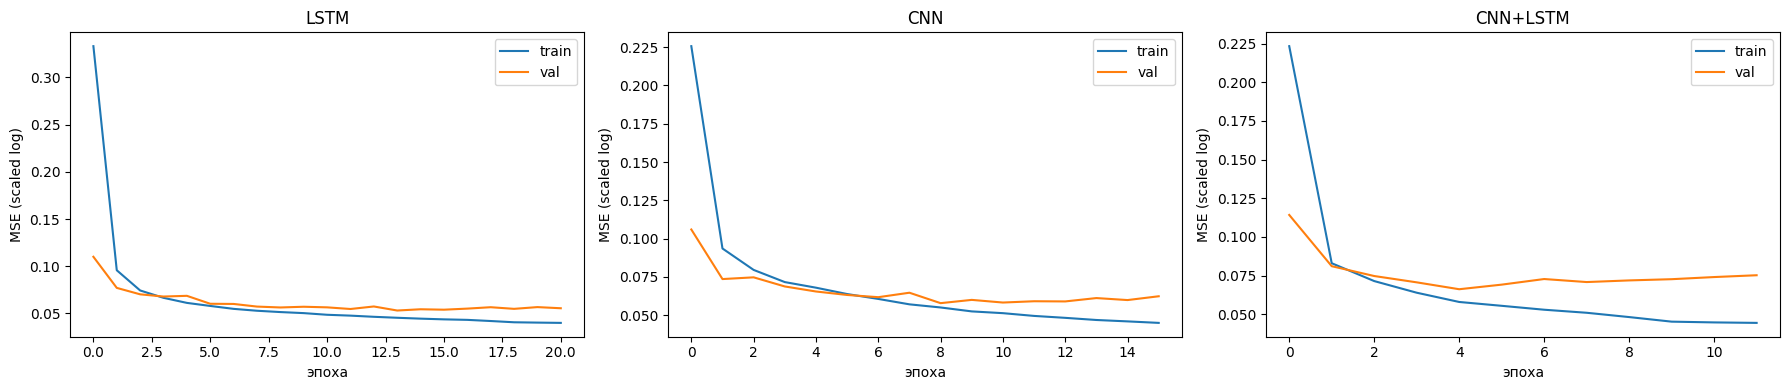

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h["train"], label="train")
    ax.plot(h["val"], label="val")
    ax.set_title(name)
    ax.set_xlabel("эпоха")
    ax.set_ylabel("MSE (scaled log)")
    ax.legend()
plt.tight_layout()
plt.show()

# Сравнение моделей

,RMSE,MAE,R2
model,,,
CNN,55.040,35.442,0.890
LSTM,64.673,42.203,0.848
CNN+LSTM,65.935,43.775,0.842
SARIMAX,99.147,62.074,0.642
Naive (сутки назад),100.751,59.289,0.630
Naive (неделя назад),111.005,64.378,0.551
Naive (последний час),212.701,154.488,-0.647


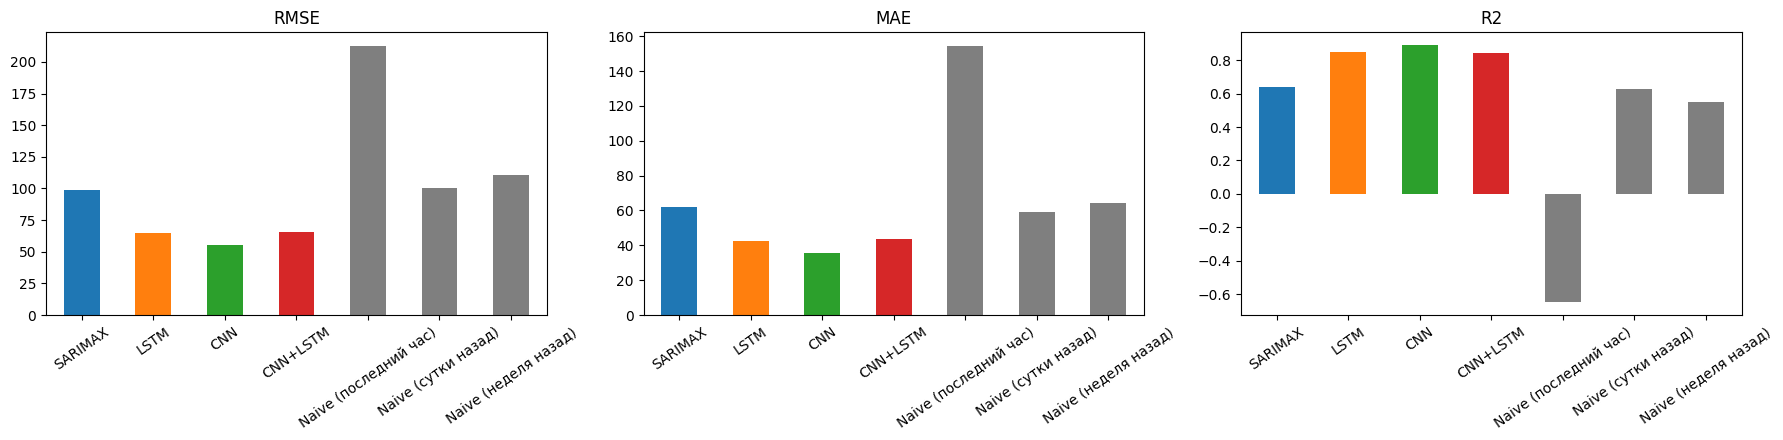

In [88]:
MAIN = ["SARIMAX", "LSTM", "CNN", "CNN+LSTM"]
NAIVE = ["Naive (последний час)", "Naive (сутки назад)", "Naive (неделя назад)"]
MODELS = MAIN + NAIVE

results = pd.DataFrame([metrics(predictions[m], m) for m in MODELS]).set_index("model")
display(results.sort_values("RMSE").round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    results[metric].plot.bar(ax=ax, rot=35, color=["C0", "C1", "C2", "C3", "C7", "C7", "C7"])
    ax.set_title(metric)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

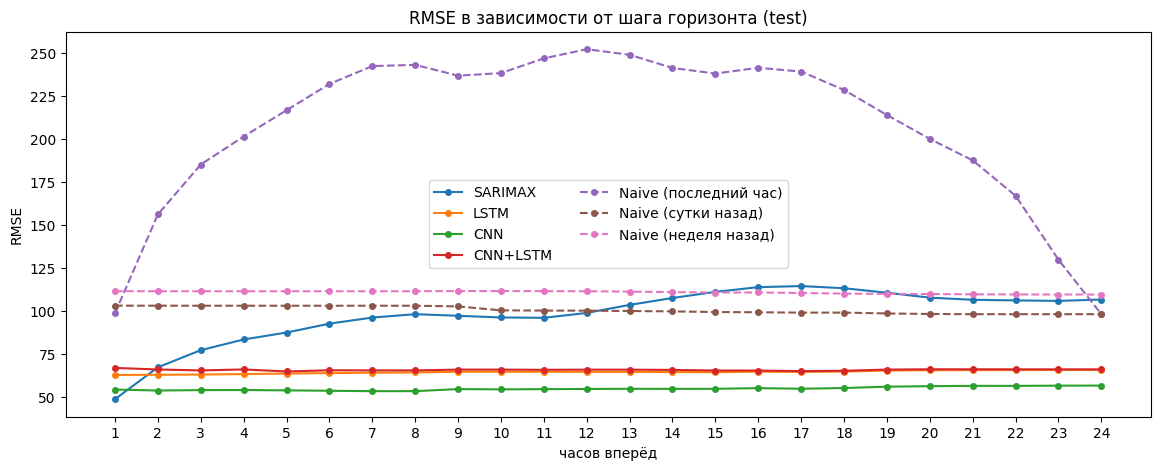

,SARIMAX,LSTM,CNN,CNN+LSTM,Naive (последний час),Naive (сутки назад),Naive (неделя назад)
часов вперёд,,,,,,,
1,48.9,63.0,54.5,67.1,98.8,103.3,111.7
3,77.4,63.2,54.2,65.6,185.3,103.2,111.6
6,92.8,64.1,53.8,65.7,232.1,103.2,111.6
12,99.0,64.8,54.8,66.1,252.3,100.3,111.6
24,106.8,65.9,56.8,66.2,98.3,98.3,109.7


In [89]:
# как растёт ошибка с горизонтом
fig, ax = plt.subplots(figsize=(14, 5))
for name in MODELS:
    style = "--" if name in NAIVE else "-"
    ax.plot(steps + 1, rmse_by_step(predictions[name]), style, marker="o", ms=4, label=name)
ax.set_xlabel("часов вперёд")
ax.set_ylabel("RMSE")
ax.set_title("RMSE в зависимости от шага горизонта (test)")
ax.set_xticks(steps + 1)
ax.legend(ncol=2)
plt.show()

display(pd.DataFrame({m: rmse_by_step(predictions[m]) for m in MODELS}, index=steps + 1)
        .loc[[1, 3, 6, 12, 24]].round(1).rename_axis("часов вперёд"))

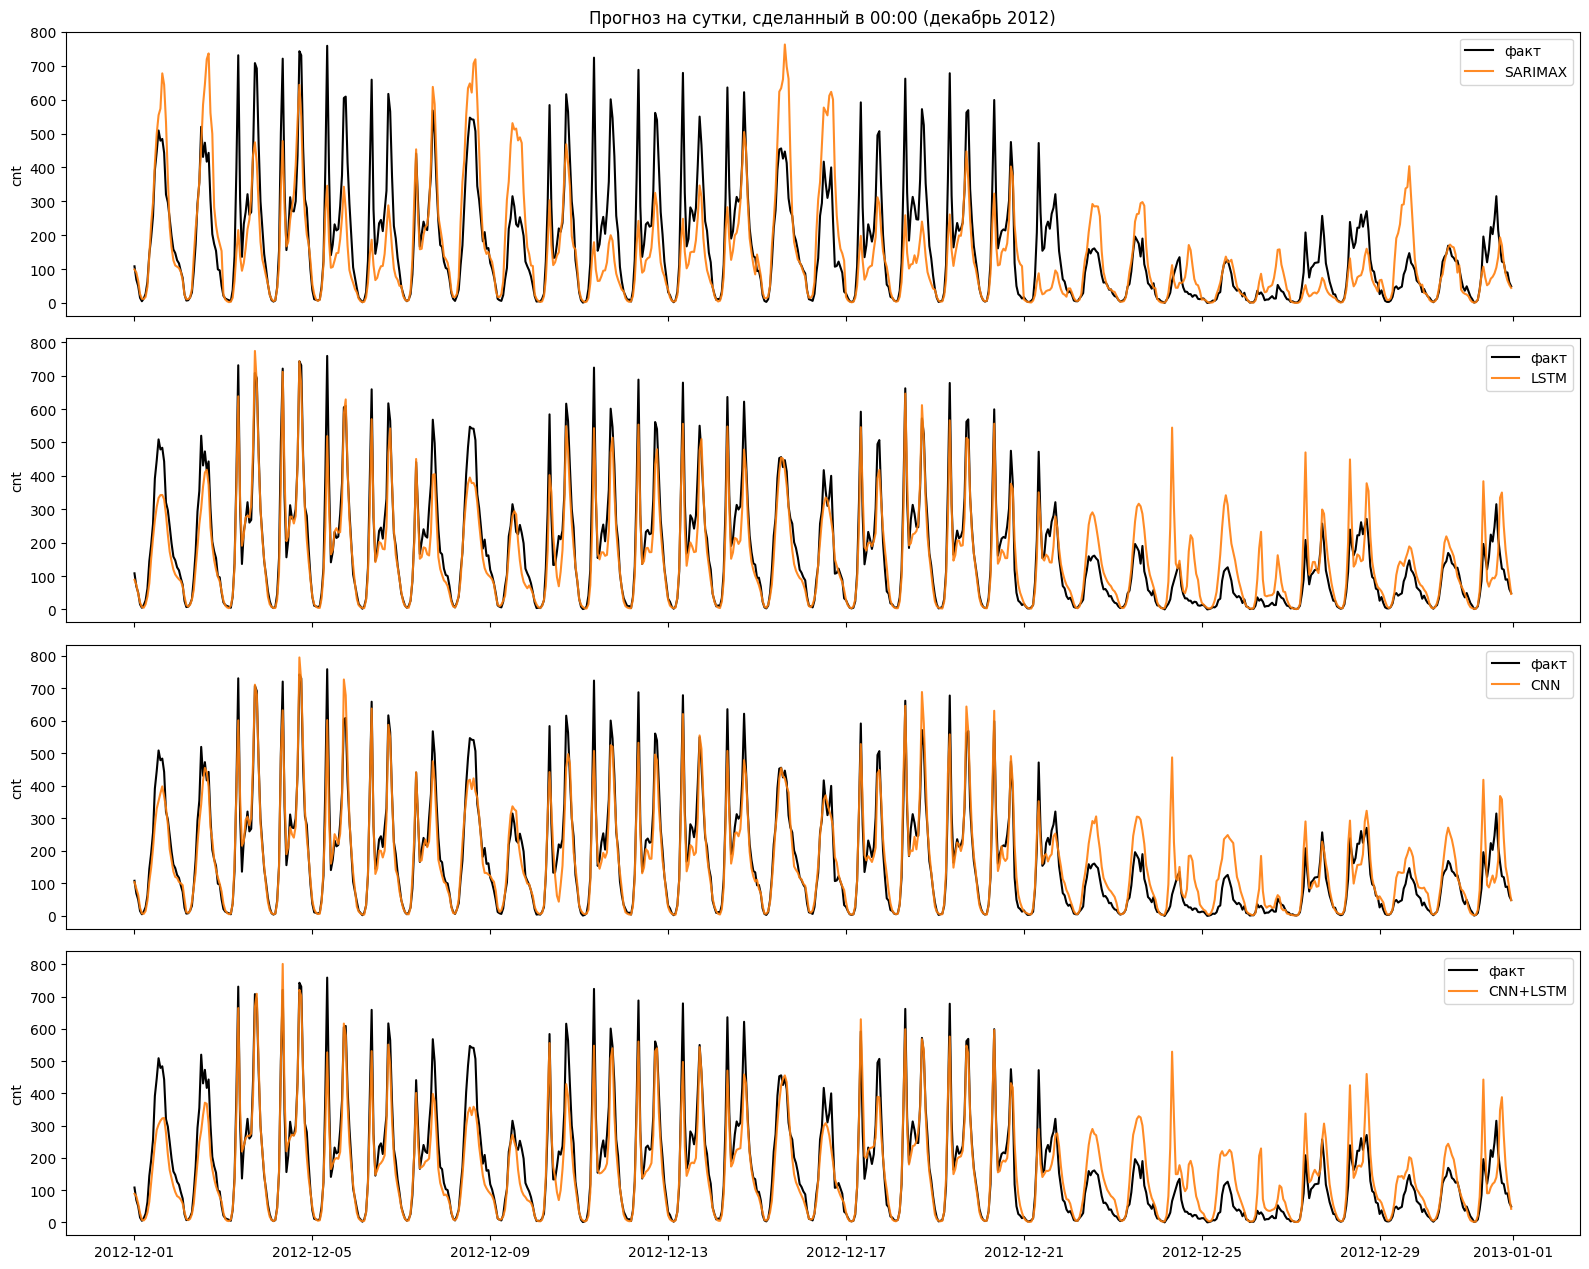

In [90]:
# сценарий «каждый день в полночь делаем прогноз на следующие сутки»: склеиваем прогнозы из точек 00:00
midnight = np.where(test_origins.hour == 0)[0]
idx = np.concatenate([pd.date_range(test_origins[i], periods=H, freq="h") for i in midnight])
fact = np.concatenate([Y_TRUE[i] for i in midnight])

fig, axes = plt.subplots(len(MAIN), 1, figsize=(16, 3.2 * len(MAIN)), sharex=True)
for ax, name in zip(axes, MAIN):
    ax.plot(idx, fact, "k", lw=1.5, label="факт")
    ax.plot(idx, np.concatenate([predictions[name][i] for i in midnight]), "C1", alpha=0.9, label=name)
    ax.set_ylabel("cnt")
    ax.legend(loc="upper right")
axes[0].set_title("Прогноз на сутки, сделанный в 00:00 (декабрь 2012)")
plt.tight_layout()
plt.show()

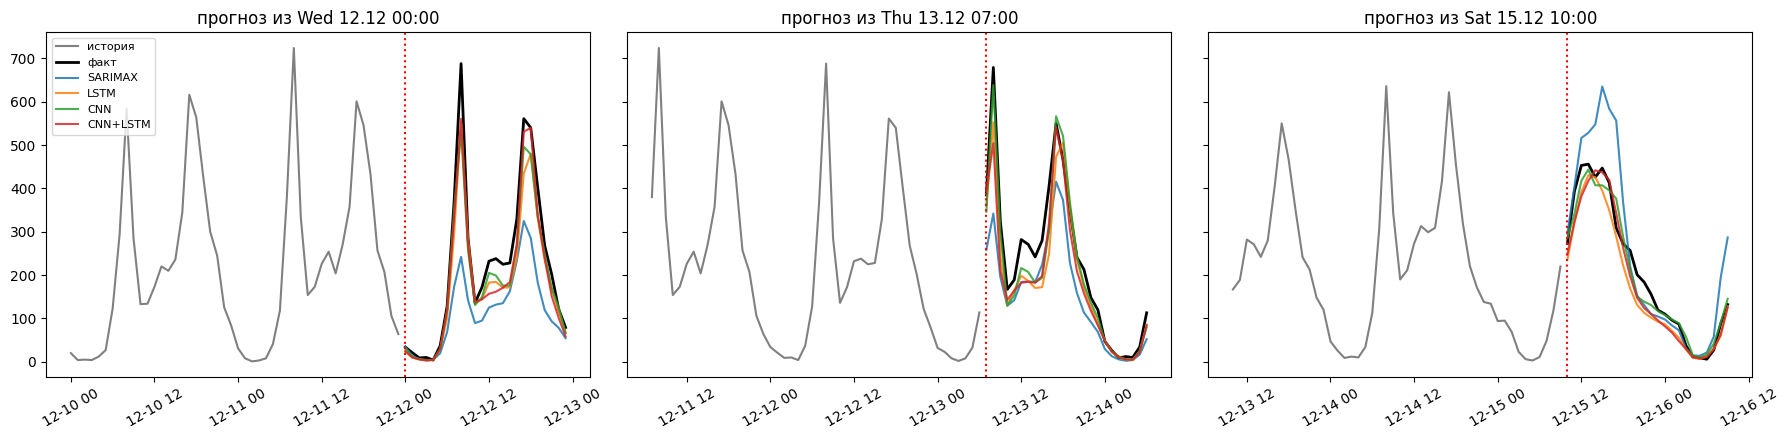

In [91]:
# несколько отдельных прогнозов: 48 часов истории + 24 часа прогноза
examples = [pd.Timestamp("2012-12-12 00:00"), pd.Timestamp("2012-12-13 07:00"), pd.Timestamp("2012-12-15 10:00")]

fig, axes = plt.subplots(1, len(examples), figsize=(18, 4.5), sharey=True)
for ax, t in zip(axes, examples):
    i = test_origins.get_loc(t)
    hist = data["cnt"].loc[t - pd.Timedelta(hours=48):t - pd.Timedelta(hours=1)]
    fut = pd.date_range(t, periods=H, freq="h")
    ax.plot(hist.index, hist.values, color="gray", label="история")
    ax.plot(fut, Y_TRUE[i], "k", lw=2, label="факт")
    for name in MAIN:
        ax.plot(fut, predictions[name][i], alpha=0.85, label=name)
    ax.axvline(t, color="red", ls=":")
    ax.set_title(f"прогноз из {t:%a %d.%m %H:%M}")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

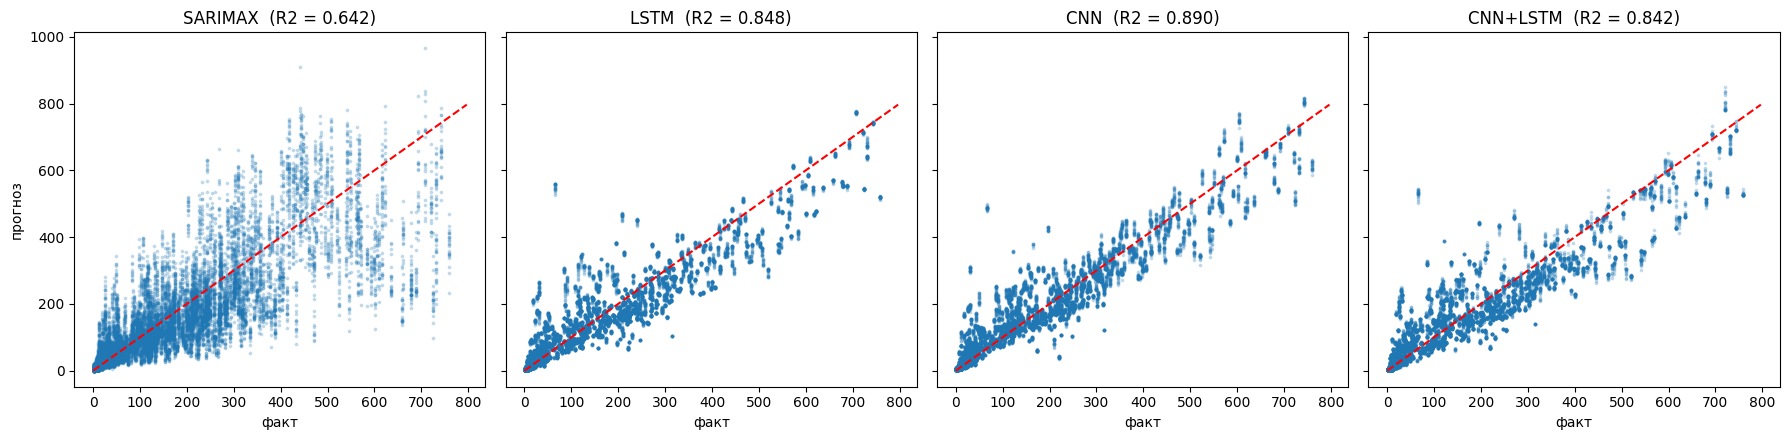

In [92]:
# факт vs прогноз (все шаги горизонта)
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharex=True, sharey=True)
lim = Y_TRUE.max() * 1.05
for ax, name in zip(axes, MAIN):
    ax.scatter(Y_TRUE[OBS], predictions[name][OBS], s=3, alpha=0.2)
    ax.plot([0, lim], [0, lim], "r--")
    ax.set_title(f"{name}  (R2 = {results.loc[name, 'R2']:.3f})")
    ax.set_xlabel("факт")
axes[0].set_ylabel("прогноз")
plt.tight_layout()
plt.show()

# Модели на 1 час vs модели на 24 часа

Обучаем те же три архитектуры, но **только на 1 час вперёд**, и сравниваем с моделями на 24 часа:

1. **Прогноз на 1 час.** Что точнее: модель, обученная только на 1 ч, или 1-й шаг модели на 24 ч?
   Выше видно, что на 1-м шаге SARIMAX точнее сетей, а у сетей ошибка почти не зависит от горизонта — они «размазывают» силы на все 24 шага.
2. **Прогноз на 24 часа.** Прямая стратегия (модель на 24 ч выдаёт всё сразу) vs **рекурсивная**:
   модель на 1 ч применяется 24 раза, каждый раз подставляя свой прогноз вместо неизвестного факта. Ошибки при этом накапливаются.
3. Сводная таблица.

SARIMAX здесь одна и та же модель: её 1-й шаг — это и есть прогноз на 1 ч, а прогноз на 24 ч у неё рекурсивный по построению.

Используются переменные из разделов выше, так что ячейки выше должны быть выполнены.

In [93]:
# окна для прогноза на 1 час: LOOKBACK часов истории + 1 будущий час (тот же формат входа, что и для 24 ч)
SEQ1 = LOOKBACK + 1

X1 = np.lib.stride_tricks.sliding_window_view(A, SEQ1, axis=0).transpose(0, 2, 1).copy()   # (n, SEQ1, F)
X1[:, LOOKBACK:, Y_COL] = 0.0
X1[:, LOOKBACK:, FLAG_COL] = 1.0
if not USE_FUTURE_WEATHER:
    X1[:, LOOKBACK:, WEATHER_COLS] = 0.0
Y1 = Yz[LOOKBACK:LOOKBACK + len(X1), None].copy()     # (n, 1)
O1 = data.index[LOOKBACK:LOOKBACK + len(X1)]          # прогнозируемый час
assert len(X1) == len(Y1) == len(O1)

w1_train = O1 < VAL_START
w1_val = (O1 >= VAL_START) & (O1 < TEST_START)
w1_test = O1 >= TEST_START

g1 = torch.Generator().manual_seed(SEED)
loaders1 = {
    "train": DataLoader(TensorDataset(torch.from_numpy(X1[w1_train]), torch.from_numpy(Y1[w1_train])),
                        batch_size=BATCH, shuffle=True, drop_last=True, generator=g1),
    "val": DataLoader(TensorDataset(torch.from_numpy(X1[w1_val]), torch.from_numpy(Y1[w1_val])),
                      batch_size=BATCH, shuffle=False),
    "test": DataLoader(TensorDataset(torch.from_numpy(X1[w1_test]), torch.from_numpy(Y1[w1_test])),
                       batch_size=BATCH, shuffle=False),
}
print("X1:", X1.shape, f"| окон: train {w1_train.sum()}, val {w1_val.sum()}, test {w1_test.sum()}")

X1: (17472, 73, 16) | окон: train 16008, val 720, test 744


In [94]:
class LastStep(nn.Module):
    # те же архитектуры, что и выше: они выдают прогноз на последних H позициях входа,
    # а нам нужна только последняя — единственный будущий час (вход длины LOOKBACK + 1)
    def __init__(self, base):
        super().__init__()
        self.base = base

    def forward(self, x):
        return self.base(x)[:, -1:]              # (B, 1)


def fit(model, name, loaders):
    # тот же цикл, что train_model, но с явно переданными загрузчиками
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=3)
    loss_fn = nn.MSELoss()
    y_val = loaders["val"].dataset.tensors[1]

    history = {"train": [], "val": []}
    best_val, best_state, wait = np.inf, None, 0
    t0 = time.time()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total = 0.0
        for xb, yb in loaders["train"]:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            total += loss.item() * len(xb)
        train_loss = total / (len(loaders["train"]) * BATCH)
        val_loss = loss_fn(torch.from_numpy(predict_scaled(model, loaders["val"])), y_val).item()
        sched.step(val_loss)

        history["train"].append(train_loss)
        history["val"].append(val_loss)
        print(f"[{name}] epoch {epoch:2d}  train {train_loss:.4f}  val {val_loss:.4f}  "
              f"lr {opt.param_groups[0]['lr']:.0e}  ({time.time() - t0:.0f} с)")

        if val_loss < best_val:
            best_val, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE:
                print(f"[{name}] ранняя остановка, лучшая эпоха {epoch - wait}")
                break

    model.load_state_dict(best_state)
    return model, history

[LSTM 1h] epoch  1  train 0.3508  val 0.1199  lr 1e-03  (1 с)
[LSTM 1h] epoch  2  train 0.1093  val 0.0812  lr 1e-03  (2 с)
[LSTM 1h] epoch  3  train 0.0857  val 0.0639  lr 1e-03  (3 с)
[LSTM 1h] epoch  4  train 0.0790  val 0.0652  lr 1e-03  (4 с)
[LSTM 1h] epoch  5  train 0.0752  val 0.0588  lr 1e-03  (5 с)
[LSTM 1h] epoch  6  train 0.0674  val 0.0549  lr 1e-03  (5 с)
[LSTM 1h] epoch  7  train 0.0648  val 0.0573  lr 1e-03  (6 с)
[LSTM 1h] epoch  8  train 0.0642  val 0.0562  lr 1e-03  (7 с)
[LSTM 1h] epoch  9  train 0.0626  val 0.0524  lr 1e-03  (8 с)
[LSTM 1h] epoch 10  train 0.0595  val 0.0476  lr 1e-03  (9 с)
[LSTM 1h] epoch 11  train 0.0581  val 0.0523  lr 1e-03  (10 с)
[LSTM 1h] epoch 12  train 0.0573  val 0.0481  lr 1e-03  (10 с)
[LSTM 1h] epoch 13  train 0.0560  val 0.0492  lr 1e-03  (11 с)
[LSTM 1h] epoch 14  train 0.0552  val 0.0444  lr 1e-03  (12 с)
[LSTM 1h] epoch 15  train 0.0550  val 0.0506  lr 1e-03  (13 с)
[LSTM 1h] epoch 16  train 0.0524  val 0.0484  lr 1e-03  (14 с)
[L

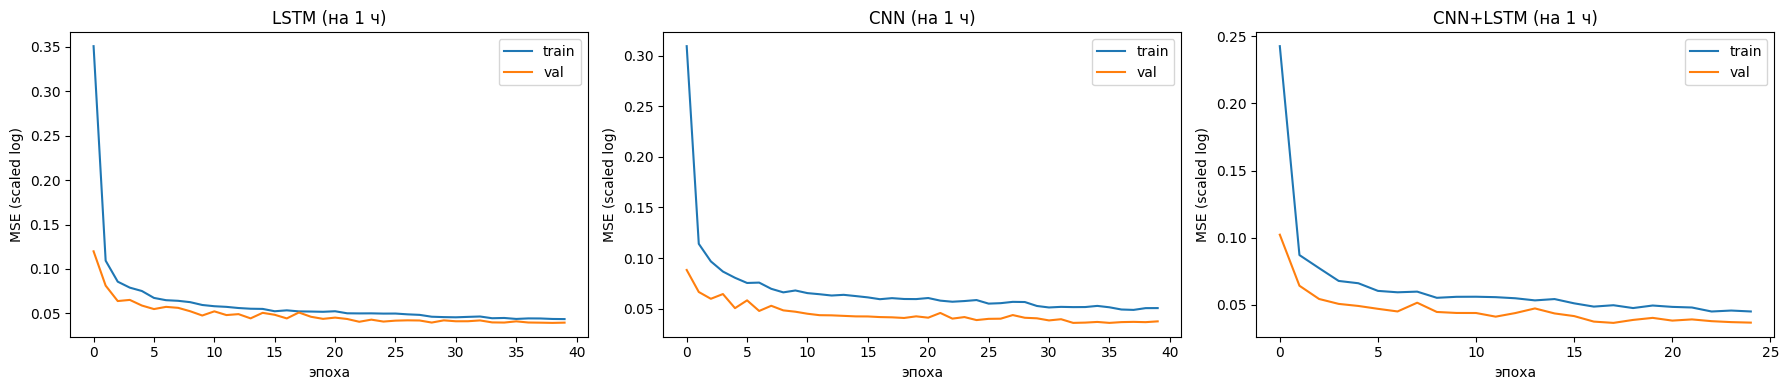

In [95]:
# обучение моделей на 1 час
nn_models_1h, histories_1h, pred_1h = {}, {}, {}

sel1 = O1[w1_test].get_indexer(test_origins)   # оцениваем на тех же точках, что и модели на 24 ч
assert (sel1 >= 0).all()

for name, cls in MODEL_CLASSES.items():
    torch.manual_seed(SEED)
    model, hist = fit(LastStep(cls(N_FEATURES)), f"{name} 1h", loaders1)
    nn_models_1h[name], histories_1h[name] = model, hist
    pred_1h[name] = to_cnt(predict_scaled(model, loaders1["test"])[sel1, 0])   # (n_origins,)
    print()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (name, h) in zip(axes, histories_1h.items()):
    ax.plot(h["train"], label="train")
    ax.plot(h["val"], label="val")
    ax.set_title(f"{name} (на 1 ч)")
    ax.set_xlabel("эпоха")
    ax.set_ylabel("MSE (scaled log)")
    ax.legend()
plt.tight_layout()
plt.show()

## 1. Прогноз на 1 час вперёд

,model,вариант,RMSE,MAE,R2
0,LSTM,обучена на 1 ч,36.302,22.985,0.952
1,LSTM,обучена на 24 ч (шаг 1),63.000,40.851,0.857
2,CNN,обучена на 1 ч,37.762,23.947,0.949
3,CNN,обучена на 24 ч (шаг 1),54.518,34.957,0.893
4,CNN+LSTM,обучена на 1 ч,37.861,24.245,0.948
5,CNN+LSTM,обучена на 24 ч (шаг 1),67.078,44.499,0.838
6,SARIMAX,шаг 1,48.883,28.413,0.914
7,Naive (последний час),-,98.824,59.305,0.647
8,Naive (сутки назад),-,103.253,60.662,0.615


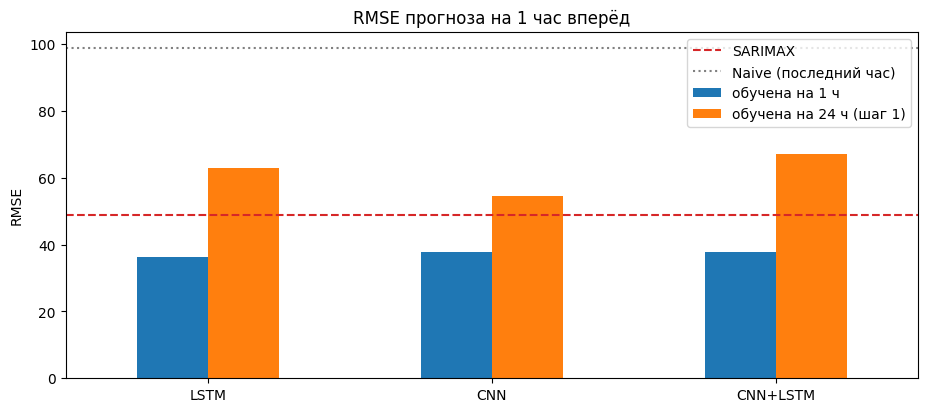

In [97]:
y1, m1 = Y_TRUE[:, 0], OBS[:, 0]

def score_1h(p, name, kind):
    return {"model": name, "вариант": kind,
            "RMSE": np.sqrt(mean_squared_error(y1[m1], p[m1])),
            "MAE": mean_absolute_error(y1[m1], p[m1]),
            "R2": r2_score(y1[m1], p[m1])}

rows = []
for name in MODEL_CLASSES:
    rows.append(score_1h(pred_1h[name], name, "обучена на 1 ч"))
    rows.append(score_1h(predictions[name][:, 0], name, "обучена на 24 ч (шаг 1)"))
rows.append(score_1h(predictions["SARIMAX"][:, 0], "SARIMAX", "шаг 1"))
rows.append(score_1h(predictions["Naive (последний час)"][:, 0], "Naive (последний час)", "-"))
rows.append(score_1h(predictions["Naive (сутки назад)"][:, 0], "Naive (сутки назад)", "-"))
cmp_1h = pd.DataFrame(rows)
display(cmp_1h.round(3))

pv = cmp_1h[cmp_1h.model.isin(MODEL_CLASSES)].pivot(index="model", columns="вариант", values="RMSE").loc[list(MODEL_CLASSES)]
ax = pv.plot.bar(rot=0, figsize=(11, 4.5))
ax.axhline(cmp_1h.set_index("model").loc["SARIMAX", "RMSE"], color="C3", ls="--", label="SARIMAX")
ax.axhline(cmp_1h.set_index("model").loc["Naive (последний час)", "RMSE"], color="gray", ls=":", label="Naive (последний час)")
ax.set_title("RMSE прогноза на 1 час вперёд")
ax.set_xlabel("")
ax.set_ylabel("RMSE")
ax.legend()
plt.show()

## 2. Прогноз на 24 часа: прямая vs рекурсивная стратегия

Рекурсия моделью на 1 ч из точки `t`:
* шаг `k = 0`: обычный прогноз часа `t` по фактической истории;
* шаг `k`: окно сдвигается на `k` часов, в истории часы `t … t+k-1` — это уже **собственные прогнозы** модели;
* погода/календарь будущих часов — как у прямой модели (если `USE_FUTURE_WEATHER = False`, погода часов `≥ t` заменяется последней известной).

Все точки прогноза обрабатываются одним батчем, так что 24 шага — это всего 24 прохода сети.

In [98]:
@torch.no_grad()
def recursive_forecast(model, origins, horizon=H):
    model.eval()
    p = data.index.get_indexer(origins)                          # позиции точек прогноза в data (= в A и Yz)
    n = len(p)
    y_buf = np.zeros((n, LOOKBACK + horizon), dtype="float32")   # y_buf[:, i] — y в момент t - LOOKBACK + i
    y_buf[:, :LOOKBACK] = Yz[p[:, None] + np.arange(-LOOKBACK, 0)]
    last_weather = A[p - 1][:, WEATHER_COLS]                     # погода в последний известный час

    for k in range(horizon):
        rows = p[:, None] + np.arange(-LOOKBACK, 1) + k          # моменты t+k-LOOKBACK ... t+k
        X = A[rows]                                              # (n, LOOKBACK+1, F), копия
        X[:, :LOOKBACK, Y_COL] = y_buf[:, k:k + LOOKBACK]       # до t — факт, начиная с t — свои прогнозы
        X[:, LOOKBACK, Y_COL] = 0.0
        X[:, LOOKBACK, FLAG_COL] = 1.0
        if not USE_FUTURE_WEATHER:
            for j in range(LOOKBACK - k, LOOKBACK):              # часы истории >= t: погода неизвестна
                X[:, j, WEATHER_COLS] = last_weather
            X[:, LOOKBACK, WEATHER_COLS] = 0.0
        y_buf[:, LOOKBACK + k] = model(torch.from_numpy(X).to(DEVICE)).cpu().numpy()[:, 0]

    return to_cnt(y_buf[:, LOOKBACK:])                           # (n, horizon)


predictions_rec = {}
for name in MODEL_CLASSES:
    predictions_rec[name] = recursive_forecast(nn_models_1h[name], test_origins)
    # проверка: 1-й шаг рекурсии должен совпасть с обычным прогнозом модели на 1 ч
    diff = np.abs(predictions_rec[name][:, 0] - pred_1h[name]).max()
    assert diff < 1.0, f"{name}: шаг 0 рекурсии не совпал с прогнозом на 1 ч (max diff {diff:.3f})"

,model,стратегия,RMSE,MAE,R2
0,LSTM,прямая (модель на 24 ч),64.673,42.203,0.848
1,LSTM,рекурсивная (модель на 1 ч),52.269,32.764,0.901
2,CNN,прямая (модель на 24 ч),55.040,35.442,0.890
3,CNN,рекурсивная (модель на 1 ч),49.957,31.209,0.909
4,CNN+LSTM,прямая (модель на 24 ч),65.935,43.775,0.842
5,CNN+LSTM,рекурсивная (модель на 1 ч),61.497,38.578,0.862
6,SARIMAX,рекурсивная (по построению),99.147,62.074,0.642
7,Naive (сутки назад),-,100.751,59.289,0.630


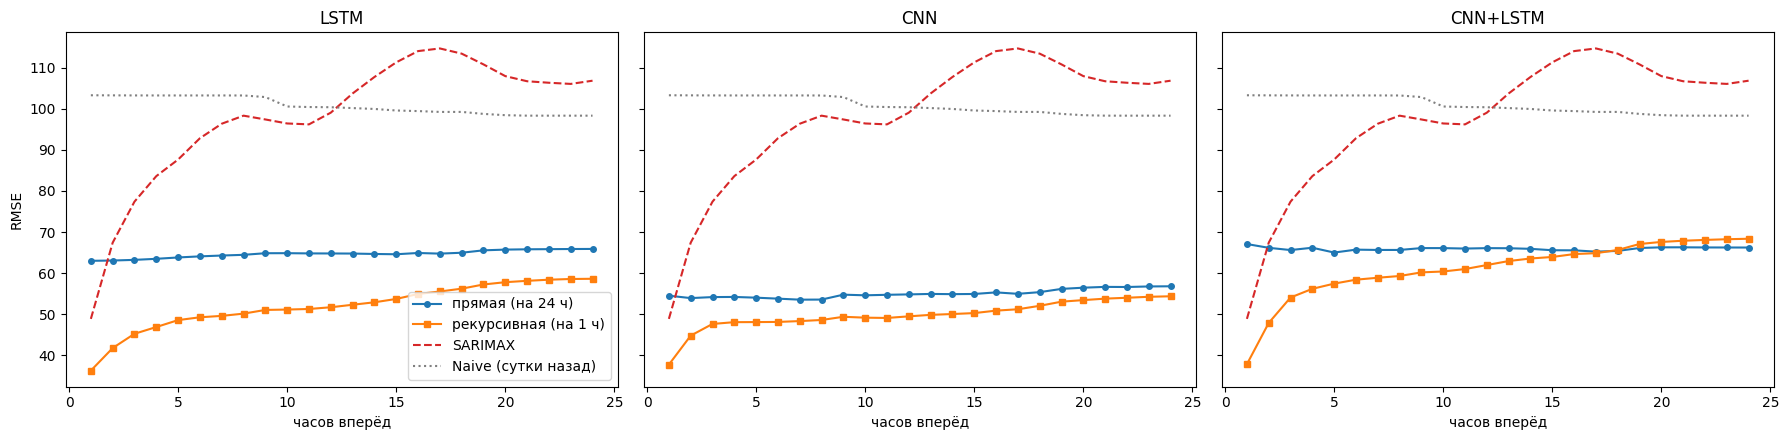

In [99]:
rows = []
for name in MODEL_CLASSES:
    rows.append({**metrics(predictions[name], name), "стратегия": "прямая (модель на 24 ч)"})
    rows.append({**metrics(predictions_rec[name], name), "стратегия": "рекурсивная (модель на 1 ч)"})
rows.append({**metrics(predictions["SARIMAX"], "SARIMAX"), "стратегия": "рекурсивная (по построению)"})
rows.append({**metrics(predictions["Naive (сутки назад)"], "Naive (сутки назад)"), "стратегия": "-"})
cmp_24h = pd.DataFrame(rows)[["model", "стратегия", "RMSE", "MAE", "R2"]]
display(cmp_24h.round(3))

# ошибка по шагам горизонта
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, name in zip(axes, MODEL_CLASSES):
    ax.plot(steps + 1, rmse_by_step(predictions[name]), "-o", ms=4, label="прямая (на 24 ч)")
    ax.plot(steps + 1, rmse_by_step(predictions_rec[name]), "-s", ms=4, label="рекурсивная (на 1 ч)")
    ax.plot(steps + 1, rmse_by_step(predictions["SARIMAX"]), "--", color="C3", label="SARIMAX")
    ax.plot(steps + 1, rmse_by_step(predictions["Naive (сутки назад)"]), ":", color="gray", label="Naive (сутки назад)")
    ax.set_title(name)
    ax.set_xlabel("часов вперёд")
axes[0].set_ylabel("RMSE")
axes[0].legend()
plt.tight_layout()
plt.show()

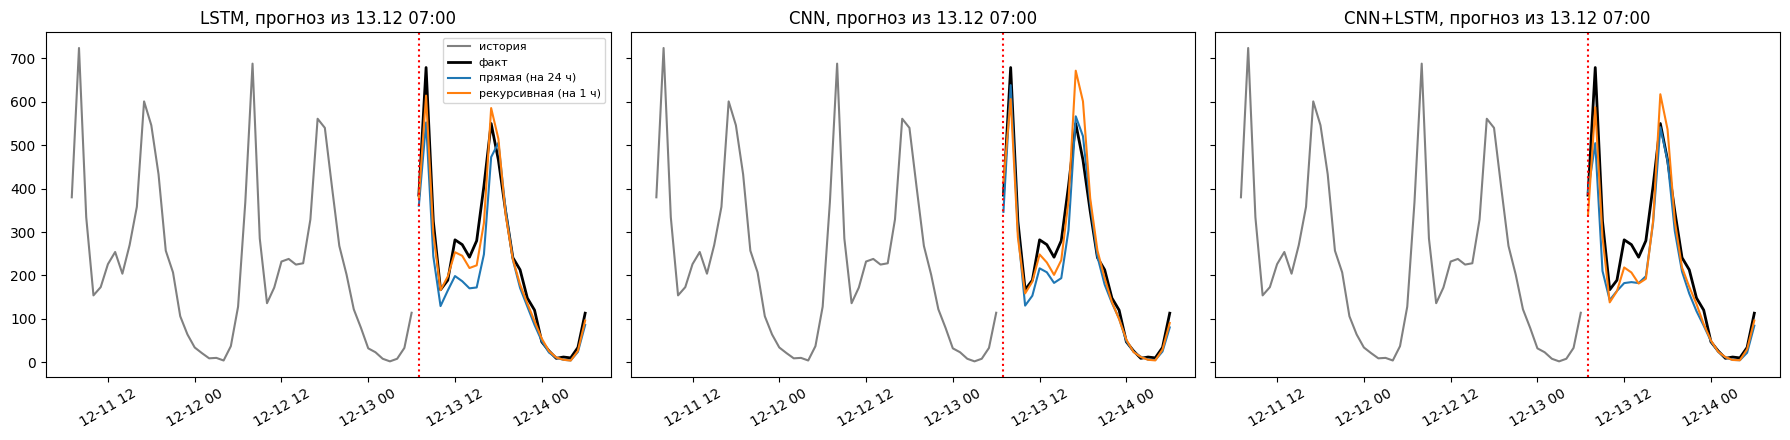

In [100]:
# пример: прямой и рекурсивный прогноз из одной точки
t = pd.Timestamp("2012-12-13 07:00")
i = test_origins.get_loc(t)
fut = pd.date_range(t, periods=H, freq="h")
hist = data["cnt"].loc[t - pd.Timedelta(hours=48):t - pd.Timedelta(hours=1)]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, name in zip(axes, MODEL_CLASSES):
    ax.plot(hist.index, hist.values, color="gray", label="история")
    ax.plot(fut, Y_TRUE[i], "k", lw=2, label="факт")
    ax.plot(fut, predictions[name][i], label="прямая (на 24 ч)")
    ax.plot(fut, predictions_rec[name][i], label="рекурсивная (на 1 ч)")
    ax.axvline(t, color="red", ls=":")
    ax.set_title(f"{name}, прогноз из {t:%d.%m %H:%M}")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Сводная таблица

In [101]:
def rmse_1h(p):
    return np.sqrt(np.mean((p[m1] - y1[m1]) ** 2))

summary = []
for name in MODEL_CLASSES:
    summary.append({"модель": name, "обучена на": "1 ч",
                    "RMSE на 1 ч": rmse_1h(pred_1h[name]),
                    "RMSE на 24 ч": metrics(predictions_rec[name], name)["RMSE"],
                    "R2 на 24 ч": metrics(predictions_rec[name], name)["R2"]})
    summary.append({"модель": name, "обучена на": "24 ч",
                    "RMSE на 1 ч": rmse_1h(predictions[name][:, 0]),
                    "RMSE на 24 ч": metrics(predictions[name], name)["RMSE"],
                    "R2 на 24 ч": metrics(predictions[name], name)["R2"]})
for name in ["SARIMAX", "Naive (последний час)", "Naive (сутки назад)"]:
    summary.append({"модель": name, "обучена на": "-",
                    "RMSE на 1 ч": rmse_1h(predictions[name][:, 0]),
                    "RMSE на 24 ч": metrics(predictions[name], name)["RMSE"],
                    "R2 на 24 ч": metrics(predictions[name], name)["R2"]})

summary = pd.DataFrame(summary).set_index(["модель", "обучена на"])
display(summary.round(3))
print("Лучшая на 1 ч: ", summary["RMSE на 1 ч"].idxmin())
print("Лучшая на 24 ч:", summary["RMSE на 24 ч"].idxmin())

RMSE на 1 ч  RMSE на 24 ч  R2 на 24 ч
модель                обучена на                                       
LSTM                  1 ч              36.302        52.269       0.901
                      24 ч             63.000        64.673       0.848
CNN                   1 ч              37.762        49.957       0.909
                      24 ч             54.518        55.040       0.890
CNN+LSTM              1 ч              37.861        61.497       0.862
                      24 ч             67.078        65.935       0.842
SARIMAX               -                48.883        99.147       0.642
Naive (последний час) -                98.824       212.701      -0.647
Naive (сутки назад)   -               103.253       100.751       0.630

Лучшая на 1 ч:  ('LSTM', '1 ч')
Лучшая на 24 ч: ('CNN', '1 ч')
